# Naive Bayes on Play Tennis
Manual implementation vs. Scikit-learn library, with comparison graph.

Code – Imports & Load Data

In [ ]:
import pandas as pd
import numpy as np
import kagglehub
import os
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB

# Load dataset
path = kagglehub.dataset_download("fredericobreno/play-tennis")
csv_path = os.path.join(path, 'play_tennis.csv')
df = pd.read_csv(csv_path)
print(df.head())

100%|██████████| 337/337 [00:00<00:00, 880kB/s]

Extracting files...
  day   outlook  temp humidity    wind play
0  D1     Sunny   Hot     High    Weak   No
1  D2     Sunny   Hot     High  Strong   No
2  D3  Overcast   Hot     High    Weak  Yes
3  D4      Rain  Mild     High    Weak  Yes
4  D5      Rain  Cool   Normal    Weak  Yes


Code – Preprocessing (Drop day)


In [ ]:
# Drop 'day' (ID) and separate target
X = df.drop(['day', 'play'], axis=1)
y = df['play']

print("Feature columns:", X.columns.tolist())
print("Target distribution:\n", y.value_counts())

Feature columns: ['outlook', 'temp', 'humidity', 'wind']
Target distribution:
 play
Yes    9
No     5
Name: count, dtype: int64


Code – Manual Naive Bayes (from your notes)


In [ ]:
def manual_naive_bayes(df, sample, alpha=1.0):
    """
    Manual Naive Bayes with Laplace smoothing (alpha=1) as in your notes.
    Returns P(Yes|X) and P(No|X) normalized.
    """
    target = 'play'
    classes = df[target].unique()
    total = len(df)
    results = {}

    for c in classes:
        prior = len(df[df[target] == c]) / total
        likelihood = 1.0
        print(f"\n--- Class: {c} ---")
        print(f"Prior P({c}) = {len(df[df[target]==c])}/{total} = {prior:.4f}")
        for col, val in sample.items():
            count = len(df[(df[target] == c) & (df[col] == val)])
            n_class = len(df[df[target] == c])
            n_unique = df[col].nunique()
            prob = (count + alpha) / (n_class + alpha * n_unique)
            likelihood *= prob
            print(f"  P({col}={val} | {c}) = ({count}+{alpha})/({n_class}+{alpha}*{n_unique}) = {prob:.4f}")
        numerator = prior * likelihood
        results[c] = numerator
        print(f"  Numerator for {c} = {numerator:.6f}")

    total_prob = sum(results.values())
    probs = {c: results[c] / total_prob for c in results}
    return probs

# Sample input
sample = pd.DataFrame({
    'outlook': ['Sunny'],
    'temp': ['Hot'],
    'humidity': ['High'],
    'wind': ['Weak']
})
sample_dict = sample.iloc[0].to_dict()

manual_probs = manual_naive_bayes(df, sample_dict)
print("\nManual Probabilities:", manual_probs)


--- Class: No ---
Prior P(No) = 5/14 = 0.3571
  P(outlook=Sunny | No) = (3+1.0)/(5+1.0*3) = 0.5000
  P(temp=Hot | No) = (2+1.0)/(5+1.0*3) = 0.3750
  P(humidity=High | No) = (4+1.0)/(5+1.0*2) = 0.7143
  P(wind=Weak | No) = (2+1.0)/(5+1.0*2) = 0.4286
  Numerator for No = 0.020499

--- Class: Yes ---
Prior P(Yes) = 9/14 = 0.6429
  P(outlook=Sunny | Yes) = (2+1.0)/(9+1.0*3) = 0.2500
  P(temp=Hot | Yes) = (2+1.0)/(9+1.0*3) = 0.2500
  P(humidity=High | Yes) = (3+1.0)/(9+1.0*2) = 0.3636
  P(wind=Weak | Yes) = (6+1.0)/(9+1.0*2) = 0.6364
  Numerator for Yes = 0.009298

Manual Probabilities: {'No': 0.687969069820332, 'Yes': 0.312030930179668}


Code – Comparison Graph

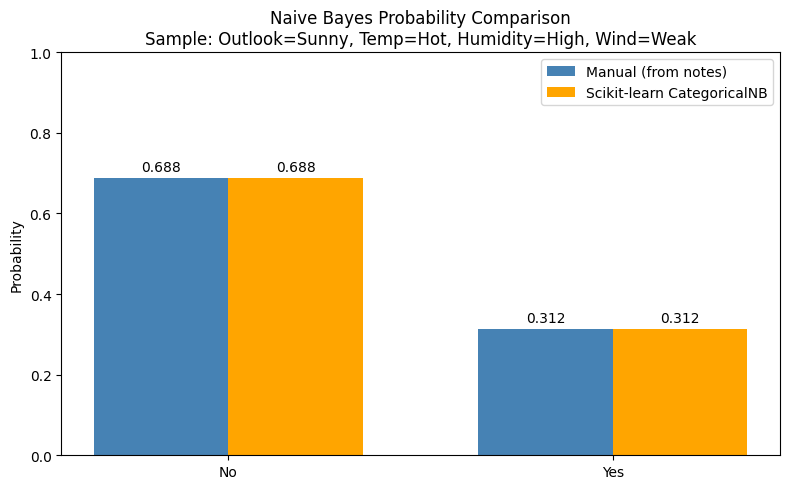

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB

# --- 1. Re-train the Library Model (Ensures variables exist) ---
# Assuming 'X', 'y', and 'sample' are defined from previous cells
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X)

model = CategoricalNB(alpha=1.0)
model.fit(X_encoded, y)

# --- 2. Get Library Probabilities ---
sample_encoded = encoder.transform(sample)
sk_probs = model.predict_proba(sample_encoded)[0]
classes = model.classes_

# Map class names to probabilities (e.g., {'No': 0.6, 'Yes': 0.4})
sk_prob_dict = {classes[i]: sk_probs[i] for i in range(len(classes))}

# --- 3. Prepare Data for Plotting ---
# Ensure manual_probs exists (from your manual calculation cell)
# If you haven't run it, here is a quick placeholder to prevent errors:
if 'manual_probs' not in locals():
    # Re-run manual calculation if missing (assuming you have the function defined)
    manual_probs = manual_naive_bayes(df, sample.iloc[0].to_dict())

labels = list(manual_probs.keys())
manual_vals = [manual_probs[c] for c in labels]
lib_vals = [sk_prob_dict[c] for c in labels]

# --- 4. Create the Graph ---
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars
bars1 = ax.bar(x - width/2, manual_vals, width, label='Manual (from notes)', color='steelblue')
bars2 = ax.bar(x + width/2, lib_vals, width, label='Scikit-learn CategoricalNB', color='orange')

# Formatting
ax.set_ylabel('Probability')
ax.set_title('Naive Bayes Probability Comparison\nSample: Outlook=Sunny, Temp=Hot, Humidity=High, Wind=Weak')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.set_ylim(0, 1)

# Annotate bars with values
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')

plt.tight_layout()
plt.show()

Code – Library Model (Scikit-learn)

In [ ]:
# Encode features
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X)

# Train CategoricalNB
model = CategoricalNB(alpha=1.0)
model.fit(X_encoded, y)

# Encode sample
sample_encoded = encoder.transform(sample)

# Predict
prediction = model.predict(sample_encoded)
sk_probs = model.predict_proba(sample_encoded)[0]

# Map class order
classes = model.classes_
sk_prob_dict = {classes[i]: sk_probs[i] for i in range(len(classes))}

print(f"Prediction: {prediction[0]}")
print(f"Library Probabilities: {sk_prob_dict}")

Prediction: No
Library Probabilities: {np.str_('No'): np.float64(0.6879690698203321), np.str_('Yes'): np.float64(0.31203093017966776)}
